# EKF 22 · Ganancia del azúcar después del primer agotamiento de YAN

Caso de referencia: modelo S del EKF 21 con azúcar inicial por densidad y dos ventanas consecutivas válidas de CO₂, sin umbral de flujo. La variante aplica el 50 % de la componente de \(S\) de la ganancia desde el siguiente paso al primer estado estimado de YAN ≤1 mg N/L. Una vez activada, la regla se mantiene hasta el final, incluido el pulso posterior si corresponde.

En cada corrección se calcula la ganancia a partir de la covarianza previa. La variante escala solo la componente de azúcar y usa la misma ganancia aplicada tanto para corregir los estados como para actualizar la covarianza mediante la forma de Joseph. Se conservan la rampa, \(Q\), \(R\), la calibración y las entradas. Las mediciones de azúcar y YAN posteriores a las iniciales se usan para evaluar.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "src/wine_fermentation").is_dir())
EKF = ROOT / "notebooks/EKF"
ORDER = ("LAB019", "LAB020", "LAB021", "LAB016", "LAB017", "LAB018",
         "LAB022", "LAB023", "LAB024")
FOCUS = ("LAB020", "LAB023", "LAB024")
ORIGINAL = "EKF 21 · sin umbral"
HALF = "Ganancia de S × 0,5"
RULES = (ORIGINAL, HALF)
STYLES = {ORIGINAL: dict(c="#D55E00", ls="--", zorder=3),
          HALF: dict(c="#0072B2", zorder=2)}


def load_reference(number, cells):
    path, = EKF.glob(f"{number}_*.source.ipynb")
    notebook = nbformat.read(path, 4)
    namespace = {"__name__": f"ekf_{number}", "display": lambda *_: None}
    for index in cells:
        source = "\n".join(line for line in notebook.cells[index].source.splitlines()
                           if not line.startswith("%matplotlib"))
        exec(compile(source, f"{path.name} :: cell {index}", "exec"), namespace)
    return namespace


def window_rule(valid):
    valid = np.asarray(valid, dtype=bool)
    return valid & np.r_[False, valid[:-1]]



## Entradas y azúcar inicial del EKF 21

In [2]:
single = load_reference(20, (1, 3, 5))
single_model = single["models"]["Q ajustado"]
def sugar_from_density(density_g_l):
    return 2.5 * (density_g_l - 1000.)


historical_density = single["v"].density.rename(
    columns={"t_h": "time", "density_g_l": "density"})
recent_density = single["prepared"]["offline"].rename(
    columns={"hours": "time", "Densidad_g_L": "density"})
density_points = {}
density_audit = []
for lab in ORDER:
    inputs = single["data"][lab]
    source = historical_density if lab in single["historical"] else recent_density
    rows = source.loc[source.lab.eq(lab), ["sample", "time", "density"]].dropna(
        subset=["time", "density"]).sort_values("time")
    initial_mask = rows.time.eq(0.) if lab in single["historical"] else rows["sample"].eq("01")
    assert initial_mask.sum() == 1, lab
    initial_density = float(rows.loc[initial_mask, "density"].iloc[0])
    density_s0 = sugar_from_density(initial_density)
    assert density_s0 > 0. and rows.loc[initial_mask, "time"].iloc[0] <= inputs["grid"][0]
    validation = rows.loc[~initial_mask & rows.time.between(inputs["grid"][0], inputs["grid"][-1])]
    assert not validation.empty, lab
    density_points[lab] = dict(
        initial_time=inputs["grid"][0], initial_sugar=density_s0,
        times=validation.time.to_numpy(), sugar=sugar_from_density(validation.density.to_numpy()))
    initial = inputs["initial"].copy()
    previous_s0 = initial[2]
    initial[2] = density_s0
    np.testing.assert_array_equal(np.delete(initial, 2), np.delete(inputs["initial"], 2))
    single["data"][lab] = {**inputs, "initial": initial}
    density_audit.append({"LAB": lab, "Densidad inicial [g/L]": initial_density,
                          "S inicial anterior [g/L]": previous_s0,
                          "S inicial por densidad [g/L]": density_s0,
                          "Muestras de validación": len(validation)})
density_audit = pd.DataFrame(density_audit).set_index("LAB")
display(density_audit.round(3))


kLa y ganancia: 0.13796553316180868 0.6586783889606775


,Densidad inicial [g/L],S inicial anterior [g/L],S inicial por densidad [g/L],Muestras de validación
LAB,,,,
LAB019,1067.6,158.16,169.00,11
LAB020,1068.5,157.46,171.25,11
LAB021,1066.8,161.23,167.00,11
LAB016,1069.0,172.50,172.50,8
LAB017,1069.0,172.50,172.50,8
LAB018,1069.0,172.50,172.50,8
LAB022,1068.6,150.03,171.50,5
LAB023,1068.2,150.92,170.50,5
LAB024,1068.0,149.75,170.00,5


## Corridas de referencia y con la ganancia de S reducida

In [3]:
source20, = EKF.glob("20_*.source.ipynb")
reference_source = nbformat.read(source20, 4).cells[5].source
replay_definition = reference_source.split("def replay(inputs,model):", 1)[1].split("\nmodels =", 1)[0]
replay_definition = "def replay_half(inputs,model):" + replay_definition
for before, after in (
    ("    states=[]", "    states=[]\n    first_exhaustion=None"),
    ("                gain=P@H/variance", "                gain=P@H/variance\n"
     "                if first_exhaustion is not None:\n                    gain[2] *= .5"),
    ("        states.append(np.stack([z,free]))", "        states.append(np.stack([z,free]))\n"
     "        if first_exhaustion is None and z[1]*SCALE_EKF[1] <= YAN_THRESHOLD_G_L:\n"
     "            first_exhaustion=time"),
    ("    return np.stack(states),readings", "    return np.stack(states),readings,first_exhaustion"),
):
    assert replay_definition.count(before) == 1
    replay_definition = replay_definition.replace(before, after)
exec(compile(replay_definition, str(source20), "exec"), single)

results = {}
activations = {}
for lab in ORDER:
    inp = single["data"][lab]
    sensor = inp["sensor"]
    run_inputs = {**inp, "sensor": sensor.assign(update=window_rule(sensor.valid))}
    states_ref, gas_ref = single["replay"](run_inputs, single_model)
    results[lab, ORIGINAL] = (states_ref, gas_ref)
    print(lab, ORIGINAL, flush=True)
    states_half, gas_half, activation = single["replay_half"](run_inputs, single_model)
    results[lab, HALF] = (states_half, gas_half)
    activations[lab] = activation
    grid = inp["grid"]
    unchanged = grid <= activation if activation is not None else np.ones(len(grid), dtype=bool)
    np.testing.assert_array_equal(states_ref[unchanged], states_half[unchanged])
    np.testing.assert_array_equal(states_ref[:, 1], states_half[:, 1])
    pd.testing.assert_frame_equal(gas_ref.loc[gas_ref.t_h.le(activation)] if activation is not None else gas_ref,
                                  gas_half.loc[gas_half.t_h.le(activation)] if activation is not None else gas_half)
    pd.testing.assert_frame_equal(gas_ref[["t_h", "measured", "valid", "update"]],
                                  gas_half[["t_h", "measured", "valid", "update"]])
    print(lab, HALF, "activación:", activation, flush=True)


## Comparación de azúcar, YAN y CO₂

Las dos corridas se evalúan sobre las mismas observaciones. El azúcar se contrasta con Y15, con la conversión de densidad también mostrada en las gráficas. Para CO₂ se evalúa el flujo pronosticado antes de corregir y se calcula un RMSE de cola desde 130 h. El salto inicial de YAN se mide como el mayor cambio absoluto aplicado en una sola corrección hasta las 40 h. El máximo tardío se calcula desde la primera caída a ≤1 mg N/L después del último pulso.

In [4]:
source20_nb = nbformat.read(source20, 4)
sample_source = source20_nb.cells[11].source.split("\n\nrows = []")[0]
assert sample_source.startswith("def states_at_samples")
exec(compile(sample_source, str(source20), "exec"), single)

def observations(lab, variable):
    inputs = single["data"][lab]
    grid = inputs["grid"]
    if lab in single["historical"]:
        state = "GF" if variable == "S" else "N"
        frame = single["chemical_observations"](single["v"].chem, lab, state)
        values = frame[single["CHEMICAL_COLUMNS"][state]].to_numpy()
        if variable == "N":
            values = 1000. * values
        times = frame.t_h.to_numpy()
    else:
        name = "GLU-FRU-320" if variable == "S" else "YAN for plot"
        frame = single["holdout_chemistry"]
        frame = frame.loc[frame.lab.eq(lab) & frame["sample"].ne("01")].dropna(subset=[name])
        times, values = frame.hours.to_numpy(), frame[name].to_numpy()
    keep = (times > grid[0]) & (times <= grid[-1])
    return times[keep], values[keep]


def last_above(gas, column):
    return gas.loc[gas[column].ge(.05), "t_h"].max()


rows = []
for lab in ORDER:
    inputs = single["data"][lab]
    grid = inputs["grid"]
    for label in RULES:
        states, gas = results[lab, label]
        yan = states[:, 0, 1]*single["SCALE_EKF"][1]*1000.
        after_pulse = grid > max(inputs["pulses"])
        low_yan = np.flatnonzero(after_pulse & (yan <= 1.))
        valid = gas.loc[gas.valid & gas.t_h.ge(1.)]
        error = valid.forecast-valid.measured
        scaled_s = states[:, 0, 2]*single["SCALE_EKF"][2]
        low_sugar = np.flatnonzero(after_pulse & (scaled_s <= 1.))
        errors = {}
        for variable, index, unit_scale in (("S", 2, 1.), ("N", 1, 1000.)):
            times, values = observations(lab, variable)
            errors[variable] = np.nan
            if len(values):
                predicted = single["states_at_samples"](inputs, single_model, states, times, index)[:, 0]*unit_scale
                errors[variable] = np.sqrt(np.mean((predicted-values)**2))
        rows.append({
            "LAB": lab, "Regla": label,
            "Primer YAN ≤1 [h]": activations[lab],
            "RMSE S vs Y15 [g/L]": errors["S"],
            "RMSE YAN [mg N/L]": errors["N"],
            "S final [g/L]": scaled_s[-1],
            "Primera vez S ≤1 pospulso [h]": grid[low_sugar[0]] if len(low_sugar) else np.nan,
            "RMSE CO₂ [g/L/h]": np.sqrt(np.mean(error**2)),
            "RMSE CO₂ desde 130 h [g/L/h]": np.sqrt(np.mean(error[valid.t_h.ge(130.)]**2)),
            "Último CO₂ pronosticado ≥0,05 [h]": last_above(valid, "forecast"),
            "Último CO₂ medido ≥0,05 [h]": last_above(valid, "measured"),
            "Mayor salto YAN hasta 40 h [mg N/L]": gas.loc[gas.t_h.le(40.), "delta_yan_mg_L"].abs().max(),
            "Máximo YAN tras agotamiento pospulso [mg N/L]": yan[low_yan[0]:].max() if len(low_yan) else np.nan,
            "YAN final [mg N/L]": yan[-1],
        })
metrics = pd.DataFrame(rows).set_index(["LAB", "Regla"])
focus = metrics.loc[list(FOCUS)]
display(focus.round(4))
print(focus.round(4).to_string())
display(metrics.round(4))

sample_rows = []
for lab, hour in (("LAB020", 166.), ("LAB023", 118.+1/3), ("LAB024", 118.+1/3)):
    times, values = observations(lab, "S")
    matches = np.isclose(times, hour, rtol=0., atol=1e-8)
    assert matches.sum()==1
    t, sample = float(times[matches][0]), float(values[matches][0])
    row = {"LAB": lab, "Hora": t, "S medido por Y15 [g/L]": sample}
    for label in RULES:
        row[label] = single["states_at_samples"](single["data"][lab], single_model,
                                                results[lab, label][0], [t], 2)[0, 0]
    sample_rows.append(row)
samples_at_focus = pd.DataFrame(sample_rows).set_index("LAB")
display(samples_at_focus.round(4))
print(samples_at_focus.round(4).to_string())


                            Primer YAN ≤1 [h]  RMSE S vs Y15 [g/L]  RMSE YAN [mg N/L]  S final [g/L]  Primera vez S ≤1 pospulso [h]  RMSE CO₂ [g/L/h]  RMSE CO₂ desde 130 h [g/L/h]  Último CO₂ pronosticado ≥0,05 [h]  Último CO₂ medido ≥0,05 [h]  Mayor salto YAN hasta 40 h [mg N/L]  Máximo YAN tras agotamiento pospulso [mg N/L]  YAN final [mg N/L]
LAB    Regla                                                                                                                                                                                                                                                                                                                                               
LAB020 EKF 21 · sin umbral            82.3333              21.4667            25.4539        10.4634                            NaN            0.1183                        0.2000                              172.0                        166.5                               1.9427                        

Primer YAN ≤1 [h]  ...  YAN final [mg N/L]
LAB    Regla                                   ...                    
LAB020 EKF 21 · sin umbral            82.3333  ...                 0.0
       Ganancia de S × 0,5            82.3333  ...                 0.0
LAB023 EKF 21 · sin umbral            54.2500  ...                 0.0
       Ganancia de S × 0,5            54.2500  ...                 0.0
LAB024 EKF 21 · sin umbral            49.6667  ...                 0.0
       Ganancia de S × 0,5            49.6667  ...                 0.0

[6 rows x 12 columns]

Primer YAN ≤1 [h]  ...  YAN final [mg N/L]
LAB    Regla                                   ...                    
LAB019 EKF 21 · sin umbral            63.5833  ...                 0.0
       Ganancia de S × 0,5            63.5833  ...                 0.0
LAB020 EKF 21 · sin umbral            82.3333  ...                 0.0
       Ganancia de S × 0,5            82.3333  ...                 0.0
LAB021 EKF 21 · sin umbral            42.9167  ...                 0.0
       Ganancia de S × 0,5            42.9167  ...                 0.0
LAB016 EKF 21 · sin umbral            47.0833  ...                 0.0
       Ganancia de S × 0,5            47.0833  ...                 0.0
LAB017 EKF 21 · sin umbral            43.8333  ...                 0.0
       Ganancia de S × 0,5            43.8333  ...                 0.0
LAB018 EKF 21 · sin umbral            43.9167  ...                 0.0
       Ganancia de S × 0,5            43.9167  ...                 0.0
LAB022 EKF 21 · sin umbral            86.4167  ...                 0.0
       Ganancia de S × 0,5            86.4167  ...                 0.0
LAB023 EKF 21 · sin umbral            54.2500  ...                 0.0
       Ganancia de S × 0,5            54.2500  ...                 0.0
LAB024 EKF 21 · sin umbral            49.6667  ...                 0.0
       Ganancia de S × 0,5            49.6667  ...                 0.0

[18 rows x 12 columns]

,Hora,S medido por Y15 [g/L],EKF 21 · sin umbral,"Ganancia de S × 0,5"
LAB,,,,
LAB020,166.0000,1.35,15.2404,6.3561
LAB023,118.3333,22.18,4.4863,5.7849
LAB024,118.3333,21.57,2.9269,3.0624


## Trayectorias por lote

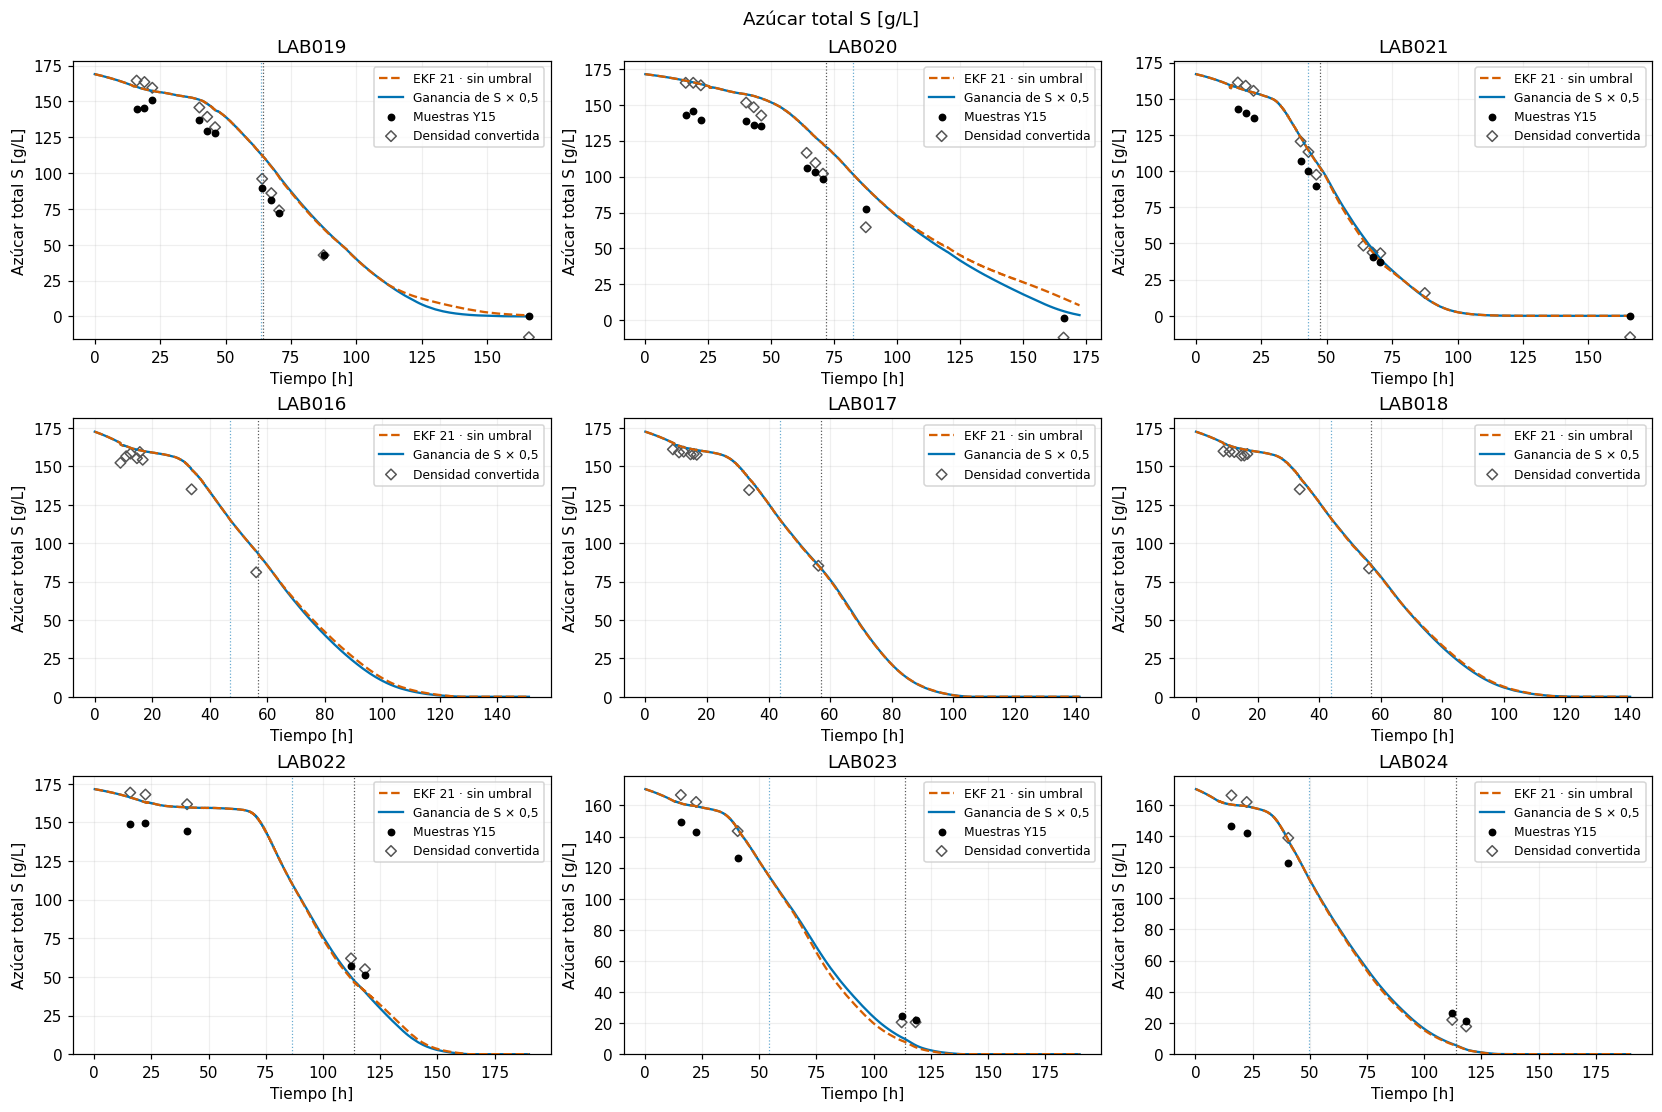

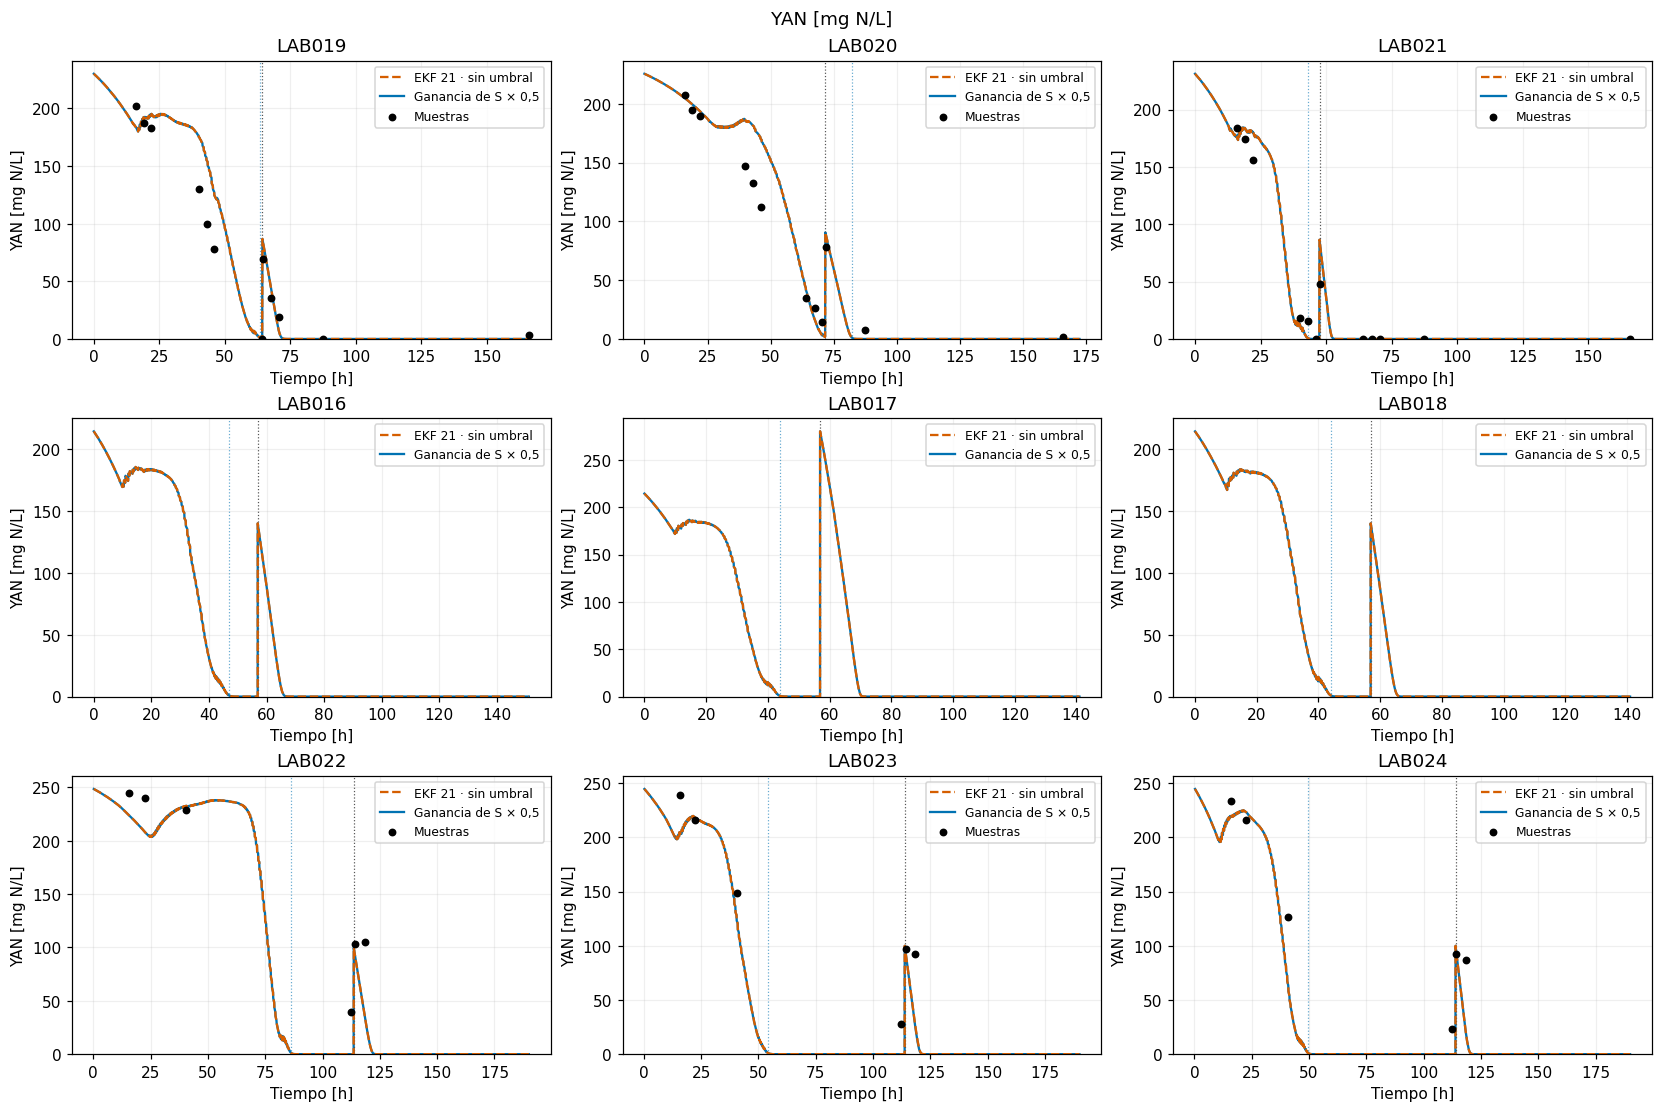

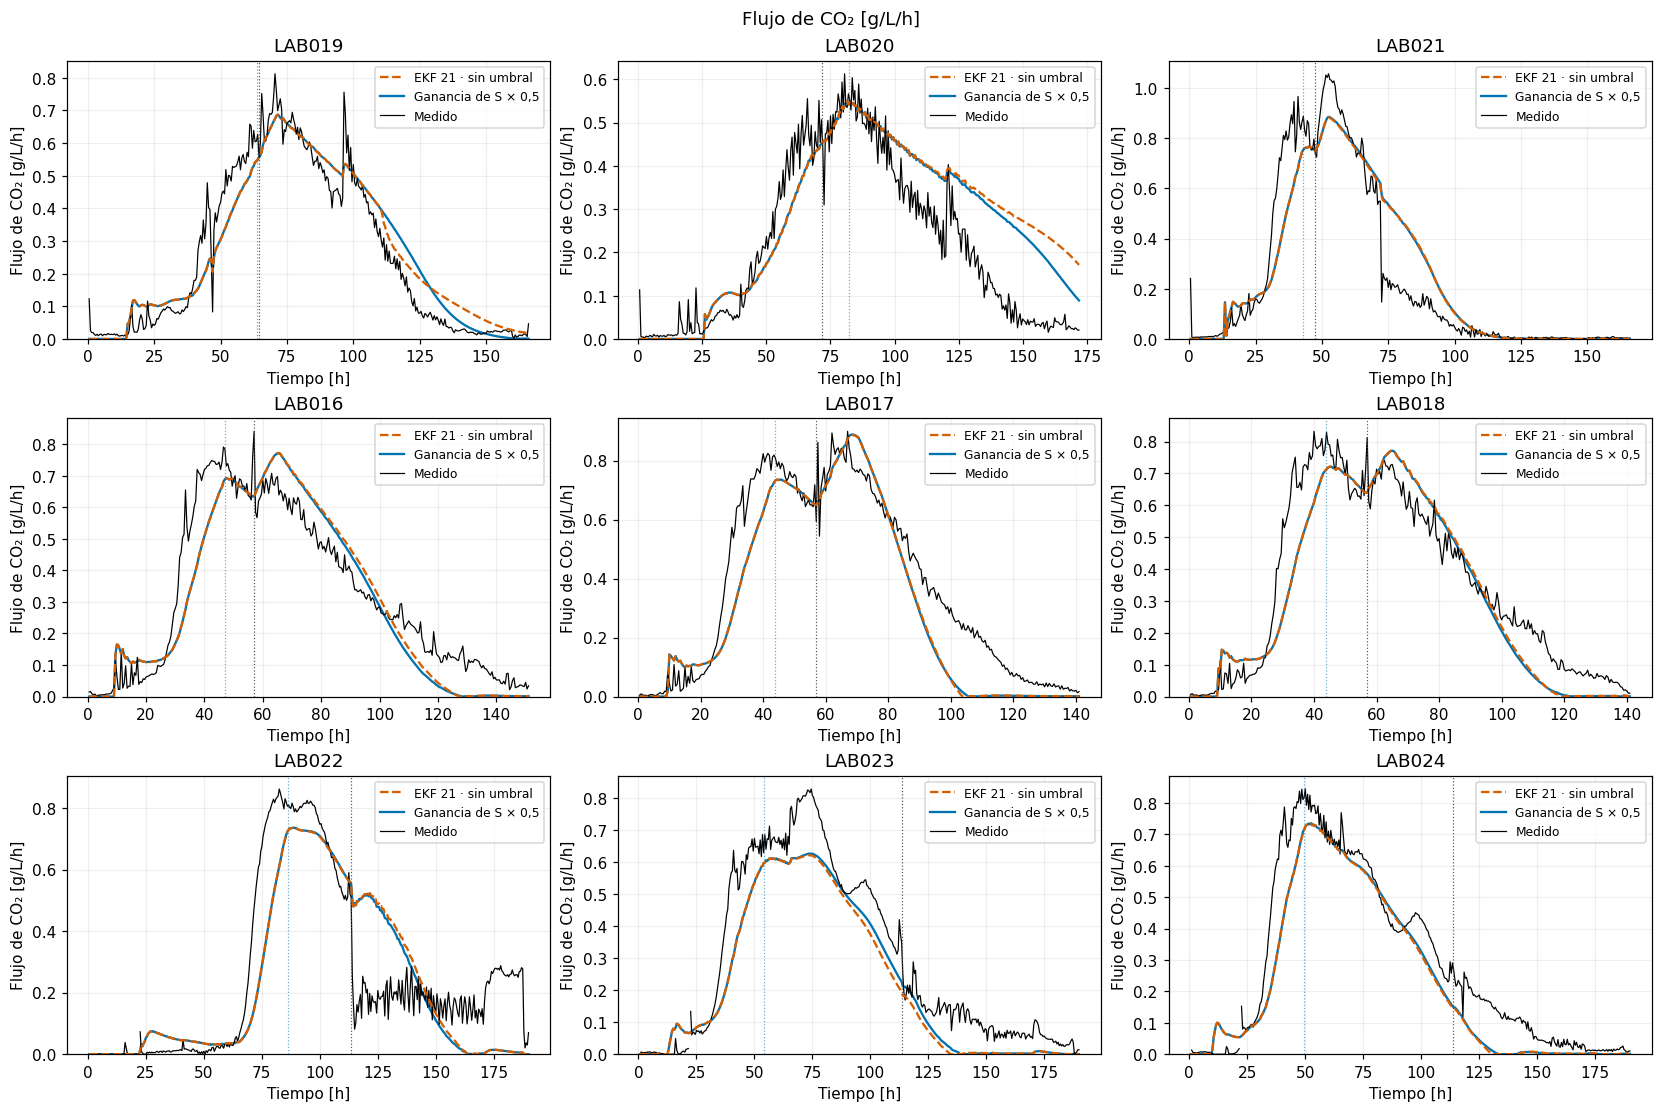

In [5]:
LABELS = {"S": "Azúcar total S [g/L]", "N": "YAN [mg N/L]", "CO2": "Flujo de CO₂ [g/L/h]"}
def draw(ax, lab, variable):
    inputs = single["data"][lab]
    grid = inputs["grid"]
    for label in RULES:
        states, gas = results[lab, label]
        if variable == "CO2":
            ax.plot(gas.t_h, gas.forecast, label=label, **STYLES[label])
        else:
            index, factor = (2, 1.) if variable == "S" else (1, 1000.)
            ax.plot(grid, states[:, 0, index]*single["SCALE_EKF"][index]*factor,
                    label=label, **STYLES[label])
    bottom = 0.
    if variable == "CO2":
        ax.plot(gas.t_h, gas.measured.where(gas.valid), c="black", lw=.8, label="Medido")
    else:
        t, samples = observations(lab, variable)
        if len(t):
            ax.scatter(t, samples, c="black", s=17, zorder=5, label="Muestras Y15" if variable=="S" else "Muestras")
        if variable == "S":
            density = density_points[lab]
            ax.scatter(density["times"], density["sugar"], marker="D", s=24,
                       facecolors="none", edgecolors="#555555", label="Densidad convertida")
            bottom = min(0., 1.1*min(density["sugar"]))
    for pulse in inputs["pulses"]:
        ax.axvline(pulse, c="#555555", ls=":", lw=.8)
    if activations[lab] is not None:
        ax.axvline(activations[lab], c=STYLES[HALF]["c"], ls=":", lw=.8, alpha=.6)
    ax.set(title=lab, xlabel="Tiempo [h]", ylabel=LABELS[variable], ylim=(bottom,None))
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)

for variable in LABELS:
    fig, axes = plt.subplots(3, 3, figsize=(15, 10), layout="constrained")
    for ax, lab in zip(axes.flat, ORDER):
        draw(ax, lab, variable)
    fig.suptitle(LABELS[variable])
    plt.show()


## LAB020 y LAB023–024 · azúcar residual, YAN pospulso y cola de CO₂

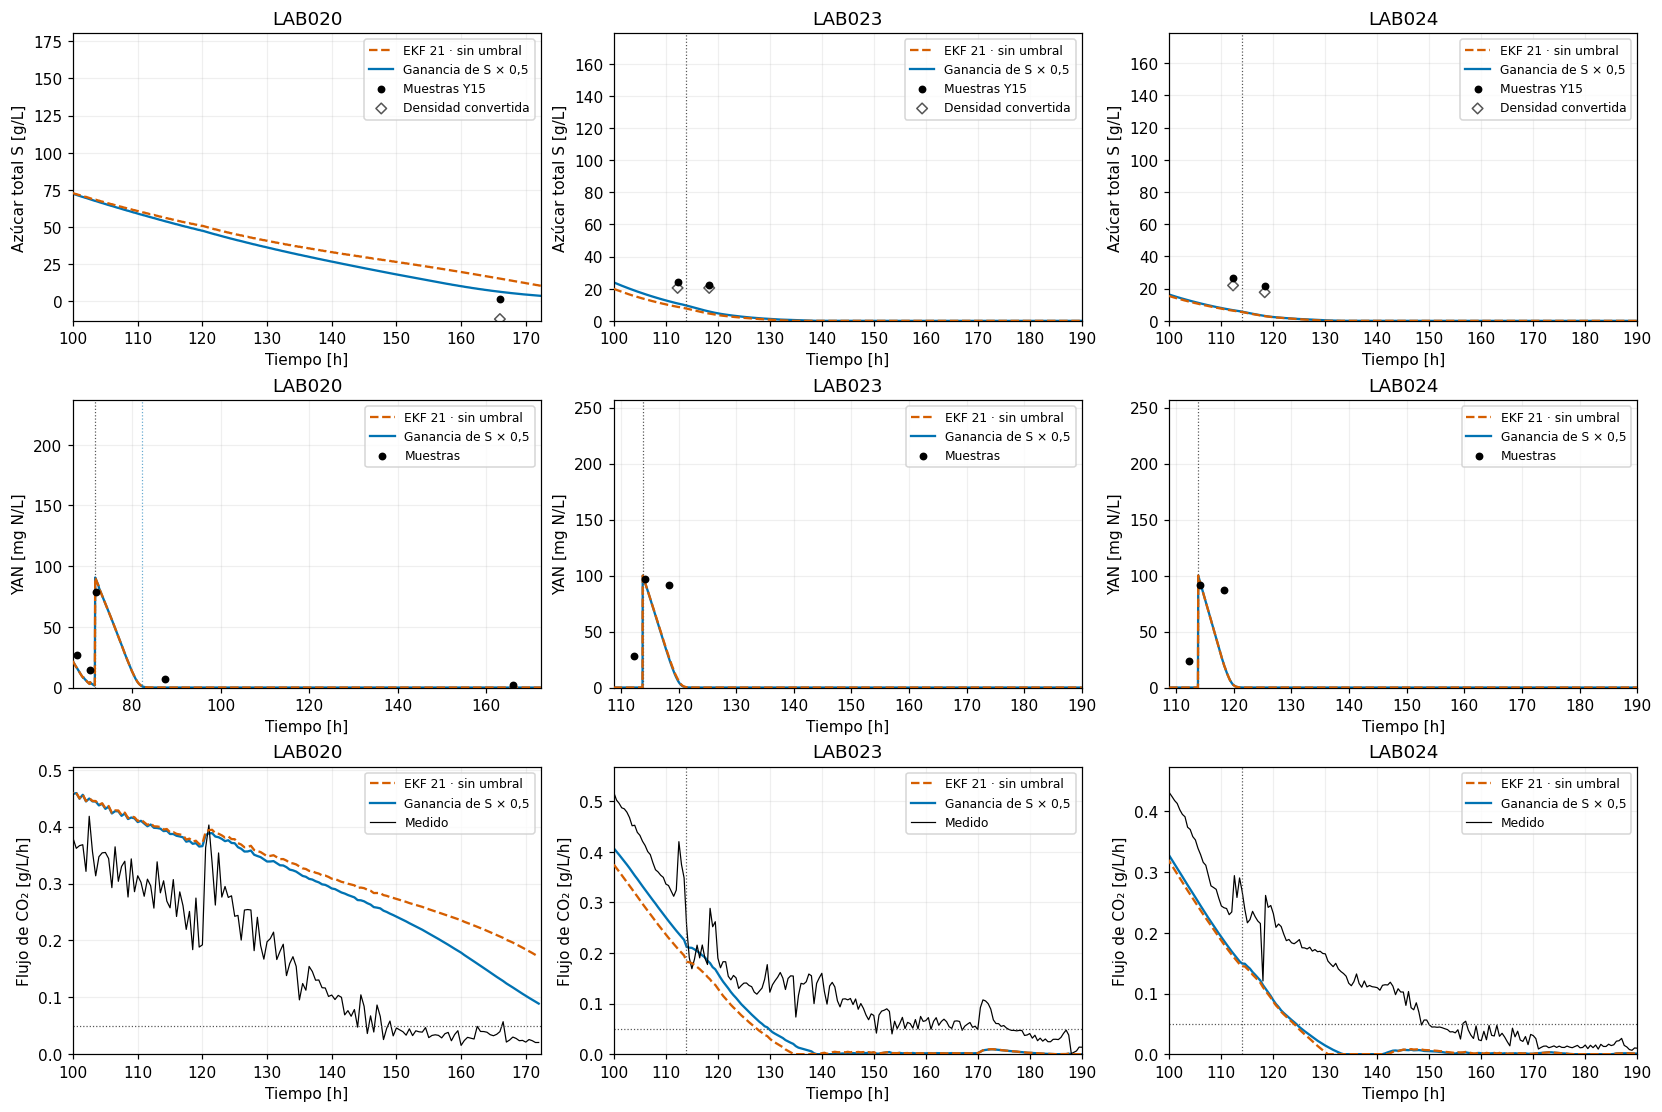

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10), layout="constrained")
for col, lab in enumerate(FOCUS):
    for row, variable in enumerate(LABELS):
        ax = axes[row, col]
        draw(ax, lab, variable)
        lo = 100. if variable != "N" else max(single["data"][lab]["pulses"])-5.
        hi = single["data"][lab]["grid"][-1]
        ax.set_xlim(lo, hi)
        if variable == "CO2":
            gas = results[lab, ORIGINAL][1]
            highest = max(max(results[lab, rule][1].loc[gas.t_h.ge(lo), "forecast"].max() for rule in RULES),
                          gas.loc[gas.t_h.ge(lo), "measured"].max())
            ax.set_ylim(0., 1.1*highest)
            ax.axhline(.05, c="#555555", ls=":", lw=.8)
plt.show()
